# 07 - Comparison methods (milestone 8)

`PROJECT_PLAN.md` §11: ICA + ICLabel (the comparison method, §11.1) and the
optional automatic-marking MWF (RELAX-style). Settings in
`configs/baselines.yaml`, fixed before any test data are touched.

mne-icalabel 0.10.0 (verified): ICLabel expects a common-average copy
band-passed 1-100 Hz and extended infomax (here picard, `ortho=False,
extended=True`). Section A runs at 128 Hz, so the copy is 1-63 Hz - a stated
limitation of the baseline. ICLabel is a neural network; it is allowed
because this is the baseline, never part of the proposed method.

The comparison below uses a Set A noise subject and **oracle** flags for the
proposed methods (the detector comes in at milestone 9); both baselines mark
artifacts themselves.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr.baselines import ica_iclabel, mwf_auto
from adr.reconstruction import check
from adr.synth import dataset3 as d3, inject as I, templates as T

RUN_CHECK = False   # True: recompute (ICA takes ~40 s per recording; ~6 min total)
table = (pd.concat([check.run(sar_db=s, baselines=True) for s in (0, -10)]) if RUN_CHECK
         else pd.read_csv(paths["results"] / "section_a" / "reconstruction_check.csv"))
order = ["no correction", "routed (oracle flags)", "single MWF (oracle flags)", "ICA+ICLabel (p>=0.7)",
         "ICA+ICLabel (p>=0.5)", "ICA+ICLabel (p>=0.9)", "auto-MWF (RELAX-style)"]
table.pivot_table(index=["sar_db", "type"], columns="pipeline", values="rrmse_analysis_flagged_excl_native")[order].round(3)

pipeline       no correction  routed (oracle flags)  single MWF (oracle flags)  ICA+ICLabel (p>=0.7)  ICA+ICLabel (p>=0.5)  ICA+ICLabel (p>=0.9)  auto-MWF (RELAX-style)
sar_db type                                                                                                                                                             
-10    motion          4.912                  0.582                      0.582                 4.910                 4.910                 4.923                   0.681
       muscle          2.018                  0.581                      0.571                 2.009                 2.018                 2.007                   0.734
       ocular          5.245                  0.753                      0.687                 2.510                 2.506                 2.502                   0.650
       pop             0.290                  0.151                      0.332                 0.657                 0.660                 0.660                   0.644
 0     motion          1.553                  0.540                      0.540                 1.640                 1.641                 1.638                   0.748
       muscle          0.638                  0.529                      0.518                 0.853                 0.879                 0.855                   0.717
       ocular          1.659                  0.716                      0.668                 0.973                 0.999                 0.938                   0.625
       pop             0.092                  0.147                      0.173                 0.626                 0.633                 0.624                   0.555

Error over the **whole** recording (1-9 Hz, native transients excluded):
both baselines change clean data too (ICA removes components everywhere;
RELAX applies its MWFs to the whole recording), while the proposed methods
only touch flagged samples.

In [3]:
table.pivot_table(index=["sar_db", "type"], columns="pipeline", values="rrmse_analysis_all_excl_native")[order].round(3)

pipeline       no correction  routed (oracle flags)  single MWF (oracle flags)  ICA+ICLabel (p>=0.7)  ICA+ICLabel (p>=0.5)  ICA+ICLabel (p>=0.9)  auto-MWF (RELAX-style)
sar_db type                                                                                                                                                             
-10    motion          2.666                  0.316                      0.316                 2.700                 2.700                 2.704                   0.641
       muscle          0.860                  0.249                      0.244                 1.020                 1.040                 0.979                   0.727
       ocular          2.314                  0.334                      0.304                 1.210                 1.217                 1.194                   0.579
       pop             0.118                  0.062                      0.135                 0.636                 0.646                 0.635                   0.567
 0     motion          0.843                  0.293                      0.293                 1.032                 1.034                 1.028                   0.634
       muscle          0.272                  0.226                      0.222                 0.650                 0.686                 0.643                   0.621
       ocular          0.732                  0.318                      0.295                 0.652                 0.689                 0.596                   0.553
       pop             0.037                  0.060                      0.071                 0.625                 0.633                 0.623                   0.553

## What the baselines remove / mark

In [4]:
display(table[table["pipeline"] == "ICA+ICLabel (p>=0.7)"][["sar_db", "type", "removed"]])
table[table["pipeline"] == "auto-MWF (RELAX-style)"][["sar_db", "type", "marked"]]

,sar_db,type,removed
3,0,ocular,"{'eye blink': 3, 'muscle artifact': 11, 'chann..."
10,0,muscle,"{'eye blink': 2, 'muscle artifact': 11, 'chann..."
17,0,motion,"{'eye blink': 3, 'muscle artifact': 11, 'chann..."
24,0,pop,"{'eye blink': 2, 'muscle artifact': 12, 'chann..."
31,-10,ocular,"{'eye blink': 6, 'muscle artifact': 7, 'channe..."
38,-10,muscle,"{'heart beat': 1, 'muscle artifact': 11, 'eye ..."
45,-10,motion,"{'eye blink': 5, 'muscle artifact': 10, 'chann..."
52,-10,pop,"{'eye blink': 2, 'muscle artifact': 13, 'chann..."


,sar_db,type,marked
6,0,ocular,"muscle 0.78, blink 0.02"
13,0,muscle,"muscle 0.81, blink 0.01"
20,0,motion,"muscle 0.83, blink 0.01"
27,0,pop,"muscle 0.77, blink 0.01"
34,-10,ocular,"muscle 0.79, blink 0.12"
41,-10,muscle,"muscle 0.81, blink 0.01"
48,-10,motion,"muscle 0.84, blink 0.01"
55,-10,pop,"muscle 0.77, blink 0.01"


## ICLabel on one recording

Top class and probability of every component for an ocular recording
(SAR -10 dB). At 128 Hz many background components come out as "muscle
artifact" or "channel noise".

label
brain              23
other              14
eye blink          12
muscle artifact    10
channel noise       4
Name: count, dtype: int64

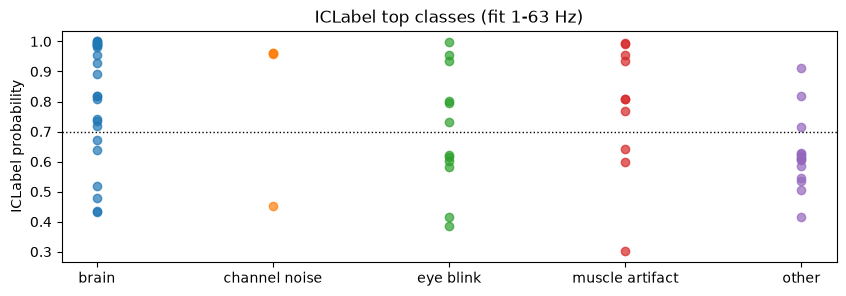

In [5]:
base, lags, _ = d3.load_base_trfs()
rec = d3.synthesize(d3.noise_source(d3.load_noise_split()["set_a"][0]), "L", -10, base, lags)
names = list(rec.ch_names)
inj = I.inject(rec.eeg, 128.0, "ocular", -10, np.random.default_rng(0), bank=T.load_bank("phantom_set_a_templates"), ch_names=names)
ica, labels, probs, band = ica_iclabel.fit_and_label(inj.eeg, 128.0, names)
comp = pd.DataFrame({"label": labels, "p": probs}).sort_values(["label", "p"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(10, 3))
for lab, grp in comp.groupby("label"):
    ax.scatter([lab] * len(grp), grp["p"], alpha=0.7)
ax.axhline(0.7, color="k", ls=":", lw=1); ax.set_ylabel("ICLabel probability"); ax.set_title(f"ICLabel top classes (fit {band[0]:.0f}-{band[1]:.0f} Hz)")
comp["label"].value_counts()

## RELAX-style marking on clean data

The muscle rule (log-log PSD slope over 7-60 Hz flatter than -0.59) on the
artifact-free synthetic recording: at 128 Hz it marks most windows, so the
RELAX default is miscalibrated for Section A (open item 14).

In [6]:
flags, starts = mwf_auto.heuristic_flags(rec.eeg, 128.0, names)
print({k: round(float(v.mean()), 2) for k, v in flags.items()})

{'ocular': 0.01, 'muscle': 0.69, 'extreme': 0.08}
